# EDA y limpieza: siniestros viales de CABA (2019-2025)

Esta notebook revisa y limpia el CSV de **hechos** del Observatorio de Movilidad y Seguridad Vial de la Ciudad. No entrena modelos. El resultado es `data/siniestros_hechos_limpio.csv` y los gráficos de `docs/figuras/`.

La pregunta que va a quedar planteada para una etapa posterior es si un siniestro fue **leve**, **grave** o **mortal**.

## Fuente

- Organismo: Observatorio de Movilidad y Seguridad Vial (GCBA).
- Ficha: <https://data.buenosaires.gob.ar/dataset/victimas-siniestros-viales>
- Hechos: <https://cdn.buenosaires.gob.ar/datosabiertos/datasets/transporte-y-obras-publicas/victimas-siniestros-viales/siniestros_viales_hechos.csv>
- Notas 2019-2025: <https://cdn.buenosaires.gob.ar/datosabiertos/datasets/transporte-y-obras-publicas/victimas-siniestros-viales/NOTAS_SINIESTROS_VIALES_2019-2025.pdf>
- Copia local y fecha de descarga: `data/ORIGEN.txt`. El archivo de hechos pesa 12.198.322 bytes, separador `;`, actualizado en el portal el 29/06/2026.

Definiciones de las notas, que se respetan tal cual:

- **Mortal:** la víctima fallece dentro de los 30 días por causas atribuibles al hecho.
- **Grave:** la lesión exigió hospitalización de al menos 24 horas.
- **Leve:** menos de 24 horas de internación, o sin traslado a un establecimiento de salud.
- Cada siniestro se clasifica por la **máxima gravedad** de sus víctimas.

La consigna de la materia limita a 3 años la antigüedad de las **referencias bibliográficas** (solo una puede ser más vieja). Esa regla no aplica al dataset. Esta base se eligió porque llega hasta 2025, supera los 5 MB y trae los tres niveles de gravedad: leve, grave y mortal. El CSV de víctimas queda afuera de esta etapa: tiene edad y sexo, pero pesa 4,1 MB y no alcanza el mínimo por sí solo.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 40)

ROOT = Path.cwd()
for candidato in [ROOT, *ROOT.parents]:
    if (candidato / "data" / "siniestros_viales_hechos.csv").exists():
        ROOT = candidato
        break

RUTA_CRUDO = ROOT / "data" / "siniestros_viales_hechos.csv"
RUTA_LIMPIO = ROOT / "data" / "siniestros_hechos_limpio.csv"
RUTA_FIGURAS = ROOT / "docs" / "figuras"
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)

SIN_DATO = {"", "SD", "#¡REF!"}
COLUMNAS_CATEGORICAS = [
    "tipo_de_via_siniestro",
    "modo_desplazamiento_victima",
    "contraparte_siniestro",
    "participantes_siniestro",
]
COLUMNAS_CONTEO = [
    "numero_victimas_leve_siniestro",
    "numero_victimas_grave_siniestro",
    "numero_victimas_mortal_siniestro",
    "numero_total_de_victimas",
]
# Estas columnas reconstruyen la etiqueta o la copian. No entran como features.
COLUMNAS_FUGA = [
    "gravedad_siniestro",
    "numero_victimas_mortal_siniestro",
    "numero_victimas_grave_siniestro",
    "numero_victimas_leve_siniestro",
    "id_siniestro",
]

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.titlesize": 13,
})
COLORES_GRAVEDAD = {"LEVE": "#8a9ba8", "GRAVE": "#e07a3d", "MORTAL": "#9b2335"}

## 1. Carga

Se leen todas las columnas como texto. Así `SD`, los vacíos y la comuna `1` no se convierten solos en nulos o en números antes de revisarlos.

In [2]:
crudo = pd.read_csv(RUTA_CRUDO, sep=";", dtype=str, encoding="utf-8-sig", keep_default_na=False)
print(f"Filas: {len(crudo):,}".replace(",", "."))
print(f"Columnas: {crudo.shape[1]}")
print(f"Tamaño del archivo: {RUTA_CRUDO.stat().st_size:,} bytes".replace(",", "."))
print("Columnas:", list(crudo.columns))
crudo.head(3)

Filas: 65.818
Columnas: 21
Tamaño del archivo: 12.198.322 bytes
Columnas: ['id_siniestro', 'numero_total_de_victimas', 'numero_victimas_leve_siniestro', 'numero_victimas_grave_siniestro', 'numero_victimas_mortal_siniestro', 'fecha_siniestro', 'anio_siniestro', 'mes_siniestro', 'dia_siniestro', 'hora_siniestro', 'rango_horario', 'direccion_normalizada_siniestro', 'comuna_siniestro', 'tipo_de_via_siniestro', 'geocodificacion_plana', 'longitud_siniestro', 'latitud_siniestro', 'participantes_siniestro', 'modo_desplazamiento_victima', 'contraparte_siniestro', 'gravedad_siniestro']


,id_siniestro,numero_total_de_victimas,numero_victimas_leve_siniestro,numero_victimas_grave_siniestro,numero_victimas_mortal_siniestro,fecha_siniestro,anio_siniestro,mes_siniestro,dia_siniestro,hora_siniestro,rango_horario,direccion_normalizada_siniestro,comuna_siniestro,tipo_de_via_siniestro,geocodificacion_plana,longitud_siniestro,latitud_siniestro,participantes_siniestro,modo_desplazamiento_victima,contraparte_siniestro,gravedad_siniestro
0,LC-2019-0000053,1,1,0,0,2019-01-01,2019,1,1,01:55:00,1,,Comuna 8,AUTOPISTA,POINT (101813.84712503915943671 95578.55507230...,-58.44351,-34.669125,AUTO-UTILITARIO,AUTO,UTILITARIO,LEVE
1,LC-2019-0000647,1,0,1,0,2019-01-01,2019,1,1,18:50:00,18,DE LOS CONSTITUYENTES AV. y HABANA,Comuna 12,AVENIDA,POINT (97510.27137648081406951 105087.83369881...,-58.490436,-34.583403,MOTO-AUTO,MOTO,AUTO,GRAVE
2,LC-2019-0000445,3,3,0,0,2019-01-01,2019,1,1,13:40:00,13,,Comuna 11,,POINT (94371.44237885093025398 102884.19365105...,-58.524662,-34.603255,AUTO-AUTO,AUTO,AUTO,LEVE


## 2. Calidad del archivo original

No hay nulos de pandas: lo que falta viene como celda vacía o como `SD` (sin dato), que es el código de las notas oficiales.

In [3]:
def vacios_y_sd(df):
    filas = []
    for columna in df.columns:
        serie = df[columna].str.strip().str.upper()
        vacios = int((serie == "").sum())
        sd = int((serie == "SD").sum())
        ref = int((serie == "#¡REF!").sum())
        if vacios or sd or ref:
            filas.append({
                "columna": columna,
                "vacios": vacios,
                "sd": sd,
                "contiene_ref": ref,
            })
    return pd.DataFrame(filas)

calidad = vacios_y_sd(crudo)
calidad

,columna,vacios,sd,contiene_ref
0,numero_total_de_victimas,0,3276,0
1,hora_siniestro,77,4,0
2,rango_horario,77,4,0
3,direccion_normalizada_siniestro,12900,729,0
4,comuna_siniestro,3017,535,0
5,tipo_de_via_siniestro,12227,315,0
6,geocodificacion_plana,2367,7,0
7,longitud_siniestro,2378,652,1
8,latitud_siniestro,2378,652,1
9,participantes_siniestro,0,0,1


In [4]:
ids = crudo["id_siniestro"].str.replace("\t", "", regex=True).str.strip()
print("IDs duplicados:", int(ids.duplicated().sum()))
print("IDs vacíos:", int((ids == "").sum()))
print("Prefijo del id:", crudo["id_siniestro"].str.slice(0, 2).value_counts().to_dict())

fecha = pd.to_datetime(crudo["fecha_siniestro"], format="mixed")
partes = crudo["fecha_siniestro"].str.split("-", expand=True)
sin_cero = int(((partes[1].str.len() < 2) | (partes[2].str.len() < 2)).sum())
desfase = (
    (crudo["anio_siniestro"].astype(int) != fecha.dt.year)
    | (crudo["mes_siniestro"].astype(int) != fecha.dt.month)
    | (crudo["dia_siniestro"].astype(int) != fecha.dt.day)
)
print(f"Fecha mínima: {fecha.min().date()}  |  Fecha máxima: {fecha.max().date()}")
print("Fechas sin mes o día en dos dígitos:", sin_cero)
print("Filas donde año, mes o día no coinciden con la fecha:", int(desfase.sum()))
print(crudo.loc[desfase, ["id_siniestro", "fecha_siniestro", "anio_siniestro", "mes_siniestro", "dia_siniestro"]])

IDs duplicados: 0
IDs vacíos: 0
Prefijo del id: {'LC': 65129, 'HC': 689}
Fecha mínima: 2019-01-01  |  Fecha máxima: 2025-12-31
Fechas sin mes o día en dos dígitos: 9406
Filas donde año, mes o día no coinciden con la fecha: 1
          id_siniestro fecha_siniestro anio_siniestro mes_siniestro dia_siniestro
56056  HC-2025-0908572      2025-11-28           2025            11            29


In [5]:
print("Gravedad")
print(crudo["gravedad_siniestro"].value_counts())
print()
print("Hechos por año")
print(crudo["anio_siniestro"].value_counts().sort_index())
print()

def a_entero(serie):
    limpio = serie.str.strip().replace({"": pd.NA, "SD": pd.NA})
    return pd.to_numeric(limpio, errors="coerce").astype("Int64")

conteos = {columna: a_entero(crudo[columna]) for columna in COLUMNAS_CONTEO}
leve, grave, mortal, total = (conteos[c] for c in COLUMNAS_CONTEO)
gravedad = crudo["gravedad_siniestro"].str.strip().str.upper()
esperada = pd.Series("LEVE", index=crudo.index)
esperada = esperada.mask(grave.fillna(0) > 0, "GRAVE")
esperada = esperada.mask(mortal.fillna(0) > 0, "MORTAL")
inconsistentes = gravedad != esperada
print("Hechos cuya gravedad no es la máxima de los conteos:", int(inconsistentes.sum()))
print(crudo.loc[inconsistentes, "anio_siniestro"].value_counts().sort_index())
print(crudo.loc[inconsistentes, ["id_siniestro", "gravedad_siniestro", *COLUMNAS_CONTEO]].head(8))

suma = leve.fillna(0) + grave.fillna(0) + mortal.fillna(0)
suma_distinta = total.notna() & (total != suma)
print()
print("Totales que no cierran con leve + grave + mortal:", int(suma_distinta.sum()))
print(crudo.loc[suma_distinta, ["id_siniestro", *COLUMNAS_CONTEO, "gravedad_siniestro"]])
print()
print("numero_total_de_victimas en SD:", int((crudo["numero_total_de_victimas"].str.strip() == "SD").sum()))
print("Esos SD, por año:", crudo.loc[crudo["numero_total_de_victimas"].str.strip() == "SD", "anio_siniestro"].value_counts().to_dict())
print("Esos SD se reconstruyen siempre como 1:", bool((suma[crudo["numero_total_de_victimas"].str.strip() == "SD"] == 1).all()))

Gravedad
gravedad_siniestro
LEVE      62174
GRAVE      2955
MORTAL      689
Name: count, dtype: int64

Hechos por año
anio_siniestro
2019    10155
2020     6061
2021     7818
2022     9536
2023     9927
2024    10569
2025    11752
Name: count, dtype: int64



Hechos cuya gravedad no es la máxima de los conteos: 31
anio_siniestro
2020    23
2024     8
Name: count, dtype: int64
          id_siniestro gravedad_siniestro numero_victimas_leve_siniestro numero_victimas_grave_siniestro numero_victimas_mortal_siniestro  \
10947  LC-2020-0080149               LEVE                              1                               1                                0   
11143  LC-2020-0096398               LEVE                              1                               1                                0   
11422  LC-2020-0119055               LEVE                              1                               1                                0   
11595  LC-2020-0134842               LEVE                              3                               2                                0   
11719  LC-2020-0144880               LEVE                              1                               1                                0   
12453  LC-2020-0248531             

In [6]:
print("Mayúsculas distintas en contraparte:")
contra = crudo["contraparte_siniestro"].str.strip()
mezcla = contra[contra.str.upper() != contra]
print(mezcla.value_counts())
print("Filas con la contraparte en minúscula:", int(len(mezcla)))
print()
print("Valores de comuna (formatos mezclados):")
print(crudo["comuna_siniestro"].value_counts())
print()
ref = crudo.apply(lambda fila: fila.str.strip().eq("#¡REF!").any(), axis=1)
print("Fila con #¡REF!:")
print(crudo.loc[ref, ["id_siniestro", "modo_desplazamiento_victima", "contraparte_siniestro", "participantes_siniestro", "latitud_siniestro", "longitud_siniestro", "gravedad_siniestro"]])
print()
print("Direcciones con '?' (ñ u otras letras perdidas en el texto):", int(crudo["direccion_normalizada_siniestro"].str.contains(r"\?", regex=True).sum()))

Mayúsculas distintas en contraparte:
contraparte_siniestro
auto      116
moto       21
camion      7
taxi        3
movil       1
peaton      1
Name: count, dtype: int64
Filas con la contraparte en minúscula: 149

Valores de comuna (formatos mezclados):
comuna_siniestro
Comuna 1     5790
Comuna 15    4361
Comuna 3     3994
Comuna 4     3720
Comuna 9     3653
Comuna 14    3648
Comuna 12    3623
Comuna 7     3537
Comuna 13    3249
Comuna 10    3133
             3017
Comuna 11    2997
Comuna 5     2619
Comuna 8     2480
Comuna 6     2255
Comuna 2     1935
1            1400
3             861
15            852
14            848
4             842
7             831
9             797
13            716
12            687
5             666
10            643
8             608
SD            535
11            534
6             517
2             415
COMUNA 1       51
COMUNA 3        3
COMUNA 15       1
Name: count, dtype: int64



Fila con #¡REF!:
          id_siniestro modo_desplazamiento_victima contraparte_siniestro participantes_siniestro latitud_siniestro longitud_siniestro  \
54066  LC-2025-0771825                      #¡REF!                #¡REF!                  #¡REF!            #¡REF!             #¡REF!   

      gravedad_siniestro  
54066               LEVE  

Direcciones con '?' (ñ u otras letras perdidas en el texto): 135


In [7]:
def falta(serie):
    return serie.str.strip().str.upper().isin(["", "SD", "#¡REF!"])

es_mortal_crudo = crudo["gravedad_siniestro"].str.strip().eq("MORTAL")
columnas_falta = [
    "modo_desplazamiento_victima",
    "contraparte_siniestro",
    "tipo_de_via_siniestro",
    "comuna_siniestro",
    "rango_horario",
    "direccion_normalizada_siniestro",
    "latitud_siniestro",
]
filas = []
for columna in columnas_falta:
    mascara = falta(crudo[columna])
    filas.append({
        "columna": columna,
        "faltantes_mortales": int((mascara & es_mortal_crudo).sum()),
        "faltantes_no_mortales": int((mascara & ~es_mortal_crudo).sum()),
    })
faltantes_por_clase = pd.DataFrame(filas)
faltantes_por_clase

,columna,faltantes_mortales,faltantes_no_mortales
0,modo_desplazamiento_victima,0,10929
1,contraparte_siniestro,10,14057
2,tipo_de_via_siniestro,0,12542
3,comuna_siniestro,0,3552
4,rango_horario,1,80
5,direccion_normalizada_siniestro,3,13626
6,latitud_siniestro,3,3028


## 3. Reglas de limpieza

No se elimina ninguna fila. La gravedad publicada se conserva, aunque en 31 hechos no coincide con la máxima de los conteos.

- Recortar espacios, tabulaciones y espacios duros.
- En tipo de vía, modo, contraparte y participantes: pasar a mayúsculas. Vacío, `SD` y `#¡REF!` pasan a `SIN_DATO`. Un valor como `SD-AUTO` se queda, porque una de las dos partes sí está informada.
- Comuna: `1`, `Comuna 1` y `COMUNA 1` quedan como `Comuna 1`. Vacío y `SD` quedan como `SIN_DATO`.
- `numero_total_de_victimas`: si dice `SD` y las tres partes suman un entero, se completa con esa suma. En este archivo son 3.276 filas de 2025 y todas suman 1. Los dos totales que no cierran (4 contra 5, y 2 contra 1) no se tocan.
- La fecha pasa a `AAAA-MM-DD`. En la única fila desfasada (`HC-2025-0908572`, fecha 28/11/2025 y día 29) manda la fecha completa, y se corrige el día.
- Hora y coordenadas: vacío, `SD` y `#¡REF!` quedan como nulo numérico en `rango_horario`, latitud y longitud. La hora en texto usa `SIN_DATO`.
- Se agrega `es_mortal`: 1 si la gravedad es `MORTAL`, 0 si es `LEVE` o `GRAVE`.
- Las direcciones con `?` se dejan como están: reparar la ñ a mano sería adivinar el nombre de la calle.
- `CAMIONETA` (74 filas) no se rebautiza a `UTILITARIO`, aunque las notas meten las camionetas en esa clase. Queda anotado para decidirlo más adelante.

In [8]:
def texto(serie):
    return (
        serie.astype("string")
        .str.replace("\xa0", " ", regex=False)
        .str.replace("\t", "", regex=False)
        .str.strip()
    )

def categorica(serie):
    salida = texto(serie).str.upper()
    return salida.mask(salida.isin(SIN_DATO), "SIN_DATO")

def limpiar_comuna(valor):
    base = valor.strip().upper().replace("COMUNA", "").strip()
    if base in {"", "SD", "SIN_DATO"}:
        return "SIN_DATO"
    if base.isdigit() and 1 <= int(base) <= 15:
        return f"Comuna {int(base)}"
    return valor.strip()

limpio = crudo.copy()
for columna in limpio.columns:
    limpio[columna] = texto(limpio[columna])

for columna in COLUMNAS_CATEGORICAS + ["gravedad_siniestro"]:
    limpio[columna] = categorica(limpio[columna])

limpio["comuna_siniestro"] = limpio["comuna_siniestro"].map(limpiar_comuna)
limpio["hora_siniestro"] = categorica(limpio["hora_siniestro"])
limpio["direccion_normalizada_siniestro"] = texto(crudo["direccion_normalizada_siniestro"]).mask(
    texto(crudo["direccion_normalizada_siniestro"]).str.upper().isin(["", "SD"]),
    "SIN_DATO",
)
geo = texto(crudo["geocodificacion_plana"])
limpio["geocodificacion_plana"] = geo.mask(
    geo.str.upper().isin(["", "SD"]) | geo.str.upper().str.contains("SD|REF", regex=True),
    "SIN_DATO",
)

for columna in COLUMNAS_CONTEO:
    limpio[columna] = a_entero(limpio[columna])

partes_ok = limpio[COLUMNAS_CONTEO[:3]].notna().all(axis=1)
total_sd = limpio["numero_total_de_victimas"].isna() & partes_ok
limpio.loc[total_sd, "numero_total_de_victimas"] = (
    limpio.loc[total_sd, COLUMNAS_CONTEO[:3]].sum(axis=1).astype("Int64")
)

fecha = pd.to_datetime(limpio["fecha_siniestro"], format="mixed")
dia_corregido = limpio["dia_siniestro"].astype(int) != fecha.dt.day
limpio["anio_siniestro"] = fecha.dt.year.astype("Int64")
limpio["mes_siniestro"] = fecha.dt.month.astype("Int64")
limpio["dia_siniestro"] = fecha.dt.day.astype("Int64")
limpio["fecha_siniestro"] = fecha.dt.strftime("%Y-%m-%d")

rango = categorica(crudo["rango_horario"])
limpio["rango_horario"] = pd.to_numeric(rango.mask(rango == "SIN_DATO"), errors="coerce").astype("Int64")
for columna in ["latitud_siniestro", "longitud_siniestro"]:
    valores = categorica(crudo[columna])
    limpio[columna] = pd.to_numeric(valores.mask(valores == "SIN_DATO"), errors="coerce")

limpio["es_mortal"] = (limpio["gravedad_siniestro"] == "MORTAL").astype("int8")

print("Filas de entrada y de salida:", len(crudo), len(limpio))
print("IDs duplicados después de limpiar:", int(limpio["id_siniestro"].duplicated().sum()))
print("Gravedades:", limpio["gravedad_siniestro"].value_counts().to_dict())
print("Comunas:", limpio["comuna_siniestro"].value_counts().sort_index().to_dict())
print("Totales SD reconstruidos:", int(total_sd.sum()))
print("Días corregidos para que coincidan con la fecha:", int(dia_corregido.sum()))
print(limpio.loc[dia_corregido, ["id_siniestro", "fecha_siniestro", "dia_siniestro"]])
print("es_mortal:", limpio["es_mortal"].value_counts().to_dict())
print("El prefijo HC coincide con es_mortal:", bool(
    (limpio["id_siniestro"].str.startswith("HC") == limpio["es_mortal"].astype(bool)).all()
))

Filas de entrada y de salida: 65818 65818
IDs duplicados después de limpiar: 0
Gravedades: {'LEVE': 62174, 'GRAVE': 2955, 'MORTAL': 689}
Comunas: {'Comuna 1': 7241, 'Comuna 10': 3776, 'Comuna 11': 3531, 'Comuna 12': 4310, 'Comuna 13': 3965, 'Comuna 14': 4496, 'Comuna 15': 5214, 'Comuna 2': 2350, 'Comuna 3': 4858, 'Comuna 4': 4562, 'Comuna 5': 3285, 'Comuna 6': 2772, 'Comuna 7': 4368, 'Comuna 8': 3088, 'Comuna 9': 4450, 'SIN_DATO': 3552}
Totales SD reconstruidos: 3276
Días corregidos para que coincidan con la fecha: 1
          id_siniestro fecha_siniestro  dia_siniestro
56056  HC-2025-0908572      2025-11-28             28
es_mortal: {0: 65129, 1: 689}
El prefijo HC coincide con es_mortal: True


In [9]:
espacio = pd.Series(False, index=crudo.index)
for columna in crudo.columns:
    original = crudo[columna].astype(str)
    recortado = original.str.replace("\xa0", " ", regex=False).str.replace("\t", "", regex=False).str.strip()
    espacio = espacio | (original != recortado)

categorias_tocadas = (
    texto(crudo["participantes_siniestro"]).str.upper().isin(SIN_DATO)
    | (texto(crudo["participantes_siniestro"]) != texto(crudo["participantes_siniestro"]).str.upper())
    | texto(crudo["modo_desplazamiento_victima"]).str.upper().isin(SIN_DATO)
    | texto(crudo["contraparte_siniestro"]).str.upper().isin(SIN_DATO)
    | (texto(crudo["contraparte_siniestro"]) != texto(crudo["contraparte_siniestro"]).str.upper())
    | texto(crudo["tipo_de_via_siniestro"]).str.upper().isin(["", "SD"])
    | texto(crudo["modo_desplazamiento_victima"]).eq("#¡REF!")
)
comuna_unificada = texto(crudo["comuna_siniestro"]) != limpio["comuna_siniestro"]
fecha_reescrita = crudo["fecha_siniestro"].str.strip() != limpio["fecha_siniestro"]
alguna = (
    categorias_tocadas
    | comuna_unificada
    | total_sd
    | fecha_reescrita
    | dia_corregido
    | espacio
    | texto(crudo["hora_siniestro"]).str.upper().isin(SIN_DATO)
    | texto(crudo["rango_horario"]).str.upper().isin(SIN_DATO)
    | texto(crudo["latitud_siniestro"]).str.upper().isin(SIN_DATO)
    | texto(crudo["direccion_normalizada_siniestro"]).str.upper().isin(["", "SD"])
    | texto(crudo["geocodificacion_plana"]).str.upper().str.contains("SD|REF", regex=True)
)
print("Filas con algún recorte de espacio o tabulación:", int(espacio.sum()))
print("Filas con comuna reescrita:", int(comuna_unificada.sum()))
print("Filas con total SD reconstruido:", int(total_sd.sum()))
print("Filas con fecha reescrita a AAAA-MM-DD:", int(fecha_reescrita.sum()))
print("Filas con el día corregido:", int(dia_corregido.sum()))
print("Filas tocadas por al menos una regla:", int(alguna.sum()))
print("Filas sin ningún cambio de limpieza:", int((~alguna).sum()))
print("No se descartó ninguna fila.")

Filas con algún recorte de espacio o tabulación: 5
Filas con comuna reescrita: 14824
Filas con total SD reconstruido: 3276
Filas con fecha reescrita a AAAA-MM-DD: 9406
Filas con el día corregido: 1
Filas tocadas por al menos una regla: 36579
Filas sin ningún cambio de limpieza: 29239
No se descartó ninguna fila.


## 4. Variable objetivo

`es_mortal` queda en el archivo como el corte de arriba: 1 si la gravedad es MORTAL y 0 si es LEVE o GRAVE. El clasificador no usa ese corte. Predice los tres niveles de `gravedad_siniestro`. Los 31 hechos marcados como leves a pesar de tener un conteo de graves siguen como LEVE: no se reescribe la etiqueta oficial.

In [10]:
n = len(limpio)
conteo = limpio["gravedad_siniestro"].value_counts()
for nivel in ["LEVE", "GRAVE", "MORTAL"]:
    print(f"{nivel}: {int(conteo[nivel])} ({conteo[nivel] / n:.2%})")
print()
por_anio = (
    limpio.groupby("anio_siniestro")
    .agg(hechos=("id_siniestro", "size"), mortales=("es_mortal", "sum"))
    .assign(tasa=lambda d: d["mortales"] / d["hechos"])
)
por_anio

LEVE: 62174 (94.48%)
GRAVE: 2955 (4.49%)
MORTAL: 689 (1.05%)


,hechos,mortales,tasa
anio_siniestro,,,
2019,10155,103,0.010143
2020,6061,79,0.013034
2021,7818,96,0.012279
2022,9536,107,0.011221
2023,9927,104,0.010476
2024,10569,110,0.010408
2025,11752,90,0.007658


## 5. Gráficos

Cada figura se guarda en `docs/figuras/` además de verse acá.

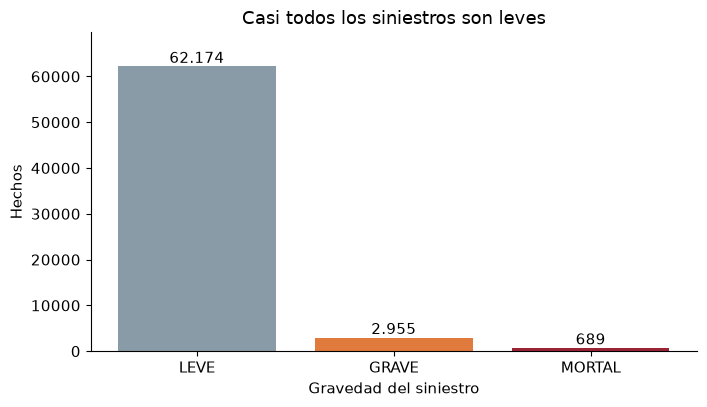

In [11]:
def guardar(figura, nombre):
    figura.tight_layout()
    figura.savefig(RUTA_FIGURAS / nombre, dpi=140, bbox_inches="tight")
    plt.show()

orden = ["LEVE", "GRAVE", "MORTAL"]
conteo = limpio["gravedad_siniestro"].value_counts().reindex(orden)
figura, eje = plt.subplots(figsize=(7.2, 4.2))
barras = eje.bar(orden, conteo.values, color=[COLORES_GRAVEDAD[g] for g in orden])
eje.set_title("Casi todos los siniestros son leves")
eje.set_ylabel("Hechos")
eje.set_xlabel("Gravedad del siniestro")
for barra, valor in zip(barras, conteo.values):
    eje.text(barra.get_x() + barra.get_width() / 2, valor, f"{valor:,}".replace(",", "."), ha="center", va="bottom")
eje.set_ylim(0, conteo.max() * 1.12)
guardar(figura, "01_gravedad.png")

De 65.818 hechos, 62.174 son leves (94,5 %), 2.955 graves (4,5 %) y 689 mortales (1,0 %). El nivel mortal es el 1 %. Más adelante, el acierto global no alcanza para elegir el modelo: predecir siempre «leve» acertaría el 94,5 %.

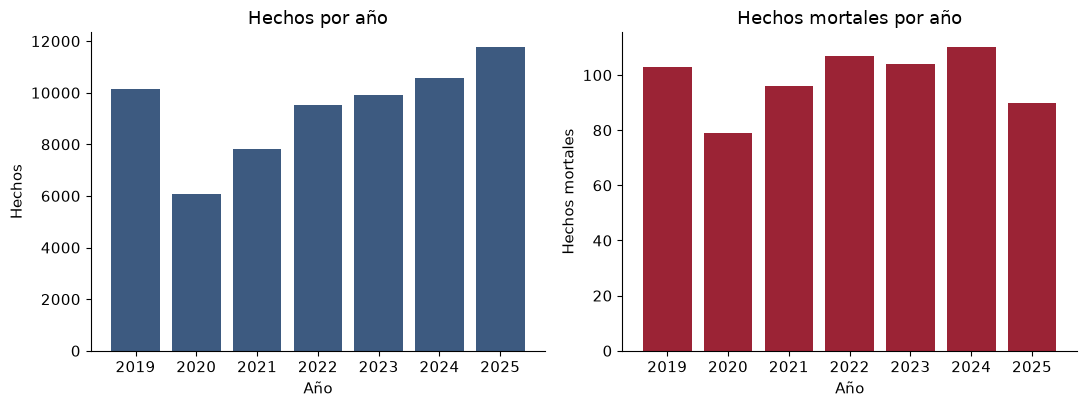

,hechos,mortales,tasa
anio_siniestro,,,
2019,10155,103,0.010143
2020,6061,79,0.013034
2021,7818,96,0.012279
2022,9536,107,0.011221
2023,9927,104,0.010476
2024,10569,110,0.010408
2025,11752,90,0.007658


In [12]:
figura, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
ejes[0].bar(por_anio.index.astype(str), por_anio["hechos"], color="#3d5a80")
ejes[0].set_title("Hechos por año")
ejes[0].set_ylabel("Hechos")
ejes[1].bar(por_anio.index.astype(str), por_anio["mortales"], color="#9b2335")
ejes[1].set_title("Hechos mortales por año")
ejes[1].set_ylabel("Hechos mortales")
for eje in ejes:
    eje.set_xlabel("Año")
guardar(figura, "02_fatales_por_anio.png")
por_anio

El volumen cae en 2020 a 6.061 hechos, frente a 10.155 en 2019, y después vuelve a subir hasta 11.752 en 2025. Los hechos mortales no siguen esa curva: se mantienen entre 79 (2020) y 110 (2024). En 2025 hay más siniestros registrados y menos mortales (90), así que la tasa baja a 0,77 %, contra 1,30 % en 2020.

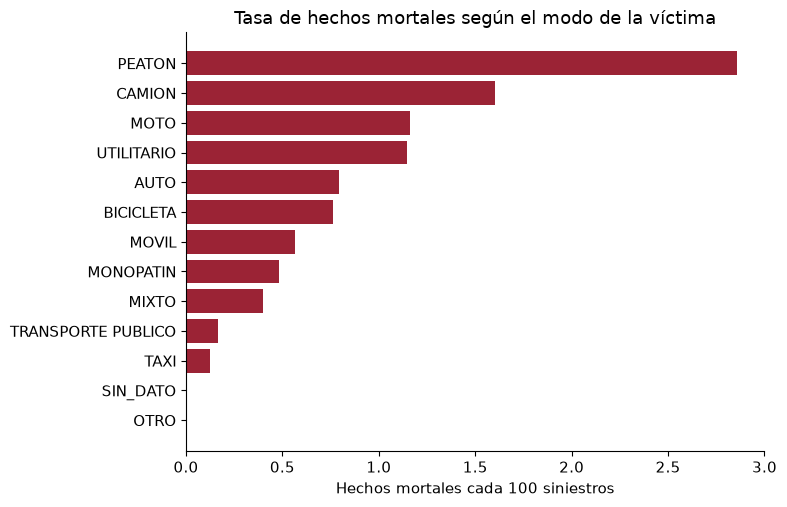

,hechos,mortales,tasa
modo_desplazamiento_victima,,,
MOTO,24555,285,0.011607
PEATON,9415,269,0.028571
AUTO,7073,56,0.007917
BICICLETA,7091,54,0.007615
UTILITARIO,697,8,0.011478
TRANSPORTE PUBLICO,3633,6,0.001652
CAMION,250,4,0.016000
MOVIL,531,3,0.005650
MIXTO,498,2,0.004016


In [13]:
modo = (
    limpio.groupby("modo_desplazamiento_victima")
    .agg(hechos=("id_siniestro", "size"), mortales=("es_mortal", "sum"))
    .assign(tasa=lambda d: d["mortales"] / d["hechos"])
    .sort_values("tasa")
)
figura, eje = plt.subplots(figsize=(8, 5.2))
colores = ["#8a9ba8" if nombre == "SIN_DATO" else "#9b2335" for nombre in modo.index]
eje.barh(modo.index, modo["tasa"] * 100, color=colores)
eje.set_title("Tasa de hechos mortales según el modo de la víctima")
eje.set_xlabel("Hechos mortales cada 100 siniestros")
guardar(figura, "03_modo_desplazamiento.png")
modo.sort_values("mortales", ascending=False)

En cantidad, la moto concentra 285 de los 689 hechos mortales y el peatón 269. En tasa, el peatón está más arriba (2,86 % de sus hechos) que la moto (1,16 %). `SIN_DATO` en el modo junta 10.929 hechos y ninguno mortal.

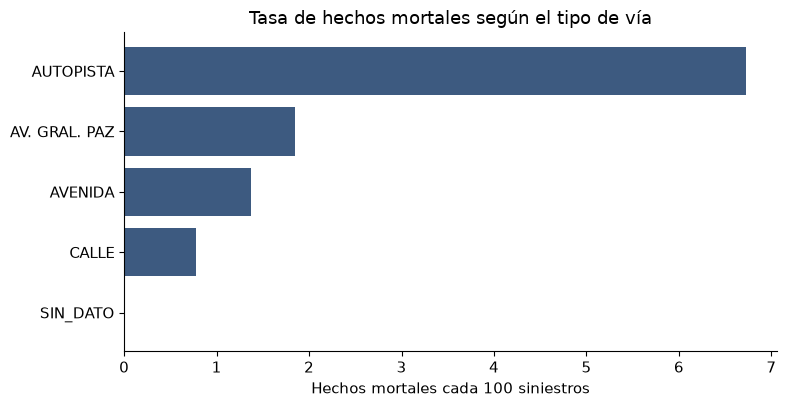

,hechos,mortales,tasa
tipo_de_via_siniestro,,,
AVENIDA,30525,419,0.013726
CALLE,18794,146,0.007768
SIN_DATO,12542,0,0.000000
AV. GRAL. PAZ,2916,54,0.018519
AUTOPISTA,1041,70,0.067243


In [14]:
via = (
    limpio.groupby("tipo_de_via_siniestro")
    .agg(hechos=("id_siniestro", "size"), mortales=("es_mortal", "sum"))
    .assign(tasa=lambda d: d["mortales"] / d["hechos"])
    .sort_values("tasa")
)
figura, eje = plt.subplots(figsize=(8, 4.2))
colores = ["#8a9ba8" if nombre == "SIN_DATO" else "#3d5a80" for nombre in via.index]
eje.barh(via.index, via["tasa"] * 100, color=colores)
eje.set_title("Tasa de hechos mortales según el tipo de vía")
eje.set_xlabel("Hechos mortales cada 100 siniestros")
guardar(figura, "04_tipo_de_via.png")
via.sort_values("hechos", ascending=False)

La autopista tiene 1.041 hechos y 70 mortales (6,72 %). La calle tiene muchos más hechos (18.794) y una tasa de 0,78 %. Avenida General Paz queda en 1,85 % y la avenida en 1,37 %. Otra vez, `SIN_DATO` (12.542 hechos, vacíos y `SD` juntos) no tiene ningún mortal.

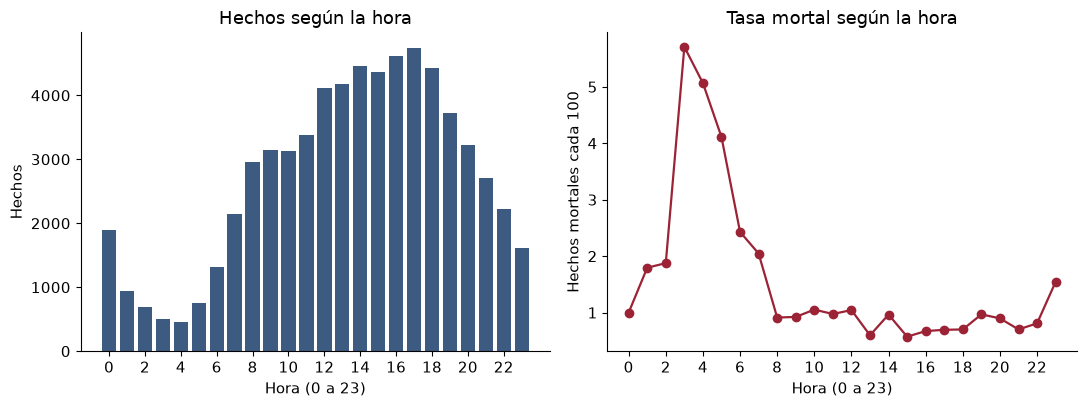

,hechos,mortales,tasa
rango_horario,,,
3,508,29,0.057087
4,454,23,0.050661
5,754,31,0.041114
15,4361,25,0.005733
16,4610,31,0.006725
17,4748,33,0.006950


In [15]:
hora = (
    limpio.dropna(subset=["rango_horario"])
    .groupby("rango_horario")
    .agg(hechos=("id_siniestro", "size"), mortales=("es_mortal", "sum"))
    .assign(tasa=lambda d: d["mortales"] / d["hechos"])
    .reindex(range(24))
)
figura, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
ejes[0].bar(hora.index, hora["hechos"], color="#3d5a80")
ejes[0].set_title("Hechos según la hora")
ejes[0].set_ylabel("Hechos")
ejes[1].plot(hora.index, hora["tasa"] * 100, color="#9b2335", marker="o", linewidth=1.6)
ejes[1].set_title("Tasa mortal según la hora")
ejes[1].set_ylabel("Hechos mortales cada 100")
for eje in ejes:
    eje.set_xlabel("Hora (0 a 23)")
    eje.set_xticks(range(0, 24, 2))
guardar(figura, "05_franja_horaria.png")
hora.loc[[3, 4, 5, 15, 16, 17]]

A la tarde se concentra el volumen (la hora 17 es la que más hechos tiene) y la tasa mortal ronda 0,6 %. Entre las 3 y las 5 hay pocos siniestros y la tasa sube a alrededor de 5 %. Hay 81 hechos sin hora; uno de ellos es mortal.

In [16]:
comuna = (
    limpio.groupby("comuna_siniestro")
    .agg(hechos=("id_siniestro", "size"), mortales=("es_mortal", "sum"))
    .assign(tasa=lambda d: d["mortales"] / d["hechos"])
    .sort_values("tasa", ascending=False)
)
comuna

,hechos,mortales,tasa
comuna_siniestro,,,
Comuna 8,3088,64,0.020725
Comuna 4,4562,75,0.016440
Comuna 10,3776,51,0.013506
Comuna 7,4368,54,0.012363
Comuna 9,4450,55,0.012360
Comuna 13,3965,44,0.011097
Comuna 1,7241,74,0.010220
Comuna 2,2350,24,0.010213
Comuna 12,4310,43,0.009977


## 6. Exportación

El CSV limpio conserva las columnas originales, ya normalizadas, y agrega `es_mortal`. Las columnas de fuga siguen en el archivo para poder auditarlas; no hay que usarlas como entrada de un modelo.

In [17]:
columnas = [c for c in crudo.columns] + ["es_mortal"]
limpio = limpio[columnas]
limpio.to_csv(RUTA_LIMPIO, sep=";", index=False, encoding="utf-8-sig")
print(RUTA_LIMPIO)
print("Bytes:", RUTA_LIMPIO.stat().st_size)
print("Filas:", len(limpio), "| Columnas:", limpio.shape[1])
print("Nulos numéricos que quedaron:")
print(limpio[["rango_horario", "latitud_siniestro", "longitud_siniestro", "numero_total_de_victimas"]].isna().sum())

D:\Cositas\Progra\sistemas-inteligentes-uni\siniestros-viales-predictor\data\siniestros_hechos_limpio.csv
Bytes: 12810312
Filas: 65818 | Columnas: 22
Nulos numéricos que quedaron:
rango_horario                 81
latitud_siniestro           3031
longitud_siniestro          3031
numero_total_de_victimas       0
dtype: int64


## 7. Qué no usar cuando se modele

Queda fuera de esta notebook. Para no perderlo:

- No usar `gravedad_siniestro`: es la etiqueta.
- No usar los tres conteos de víctimas por gravedad: alcanzan para reconstruirla. El total de víctimas no la determina, pero conviene probar el modelo con esa columna y sin ella.
- No usar el prefijo de `id_siniestro`. `HC` es mortal y `LC` es lesionado, sin excepciones en este archivo.
- `SIN_DATO` en modo, tipo de vía y comuna no aparece en los mortales. Si entra como categoría, el modelo puede estar leyendo la calidad del registro y no el siniestro.
- Edad y sexo están en el CSV de víctimas, no en este. Cruzarlos es una línea posterior.

## 8. Feriados y fin de semana

Los feriados nacionales de 2021 a 2025 salen de `https://api.argentinadatos.com/v1/feriados/{año}`. 2019 y 2020 responden 404. Esos dos años se arman con la regla de traslado, contrastada contra la API, y con los tres puentes turísticos de cada año. La lista queda en `data/feriados_nacionales_2019-2025.csv`. El gráfico de los tres tipos de día es `docs/figuras/07_calendario.png`. La tasa de cada feriado está en `docs/figuras/08_feriados_tasa.png` y en `data/feriados_por_nombre.csv`.

Un feriado que cae sábado o domingo cuenta como feriado. El fin de semana del gráfico es sábado o domingo que no es feriado. El día de semana junta más hechos por día (29,4) que el fin de semana (18,7) y que el feriado (16,3). La tasa mortal queda en 0,96 %, 1,33 % y 1,40 %. En el feriado son 31 muertes en toda la serie. Soberanía Nacional y Belgrano concentran 6 muertes cada uno. Carnaval y Memoria, Verdad y Justicia no tienen ninguna.

In [ ]:
import pandas as pd
from IPython.display import Image, display

tabla = pd.read_csv('../data/calendario_por_anio.csv')
columnas = ['anio', 'tipo', 'dias', 'hechos', 'mortales', 'hechos_por_dia', 'tasa_mortal']
print(tabla[columnas].sort_values(['anio', 'tipo']).to_string(index=False))
display(Image('../docs/figuras/07_calendario.png'))
por_nombre = pd.read_csv('../data/feriados_por_nombre.csv')
print(por_nombre.to_string(index=False))
display(Image('../docs/figuras/08_feriados_tasa.png'))